# Scratch Work for Flow Matching model 

In [29]:
from utils.atoms_to_graphs import AtomsToGraphs
from ase.io import read
import networkx as nx
from matplotlib import pyplot as plt

Graph object: Data(pos=[4, 3], cell=[1, 3, 3], atomic_numbers=[4], natoms=4, tags=[4], edge_index=[2, 14], cell_offsets=[14, 3], fixed=[4])
Number of nodes: 4
Number of edges: 14
Nodes in networkx graph: [0, 1, 2, 3]
Edges in networkx graph: [(0, 1), (0, 3), (0, 2), (1, 3), (1, 2), (2, 3)]


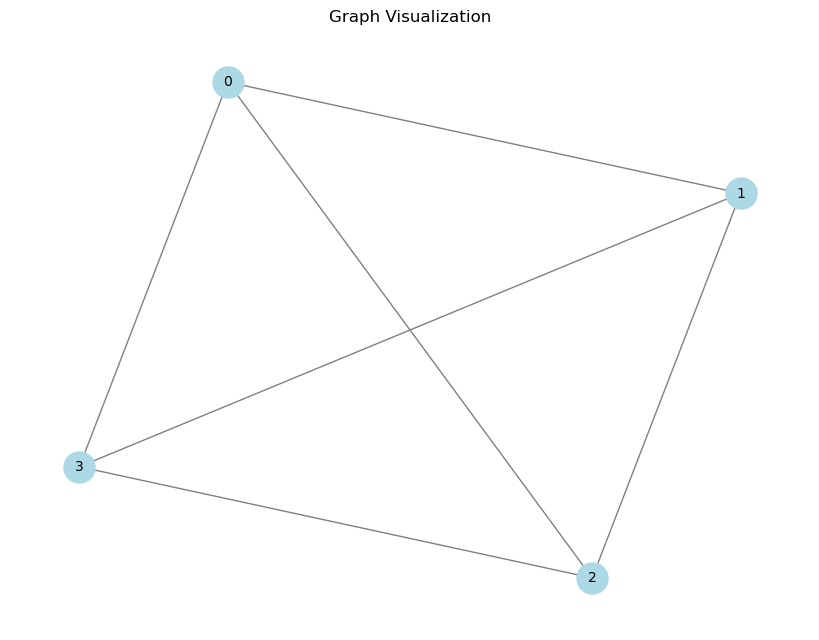

In [35]:
import networkx as nx
import matplotlib.pyplot as plt
from utils.atoms_to_graphs import AtomsToGraphs
from ase.io import read

# Load your structure using ASE
atoms = read('POSCAR')
atoms = read('no3.xyz')

# Convert the Atoms object to a graph
converter = AtomsToGraphs()
graph = converter.convert(atoms)  # Assuming this returns a PyTorch Geometric Data object

# Debug: Check the graph structure
print("Graph object:", graph)
print("Number of nodes:", graph.num_nodes)
print("Number of edges:", graph.edge_index.shape[1] if graph.edge_index is not None else 0)

# Convert the graph to a networkx graph
def pytorch_geometric_to_networkx(graph):
    import torch
    import networkx as nx

    # Extract edge indices and node features
    edge_index = graph.edge_index.numpy()  # Convert edge indices to numpy
    node_features = graph.x.numpy() if graph.x is not None else None

    # Create a networkx graph
    G = nx.Graph()

    # Add nodes
    for i in range(graph.num_nodes):
        G.add_node(i, features=node_features[i] if node_features is not None else None)

    # Add edges
    for i in range(edge_index.shape[1]):
        source, target = edge_index[:, i]
        G.add_edge(source, target)

    return G

# Convert the graph to a networkx graph
G = pytorch_geometric_to_networkx(graph)

# Debug: Check the networkx graph
print("Nodes in networkx graph:", G.nodes())
print("Edges in networkx graph:", G.edges())

# Draw the graph
plt.figure(figsize=(8, 6))
pos = nx.spring_layout(G)  # Layout for positioning nodes
nx.draw(G, pos, with_labels=True, node_color='lightblue', edge_color='gray', node_size=500, font_size=10)
plt.title("Graph Visualization")
plt.axis('off')  # Turn off the axis
plt.show()